In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from quantlab.data_loader import load_prices
from quantlab.returns import log_returns
from quantlab.stats import cov_loops, cov_vec, corr_from_cov
from quantlab.linalg_tools import ols_normal, ols_qr, ols_svd, pca_svd

r = log_returns(load_prices())
stocks = r.drop(columns="^GSPC")

In [2]:
X = np.random.default_rng(0).standard_normal((2500, 25))
print(np.allclose(cov_loops(X), cov_vec(X)), np.allclose(cov_vec(X), np.cov(X, rowvar=False)))
%timeit -n 1 -r 1 cov_loops(X)
%timeit cov_vec(X)
%timeit np.cov(X, rowvar=False)

True True
2.6 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
765 μs ± 50.2 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
906 μs ± 75.4 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [3]:
S = cov_vec(stocks.to_numpy())
print("symmetric:", np.allclose(S, S.T))
print("smallest eigenvalue:", np.linalg.eigvalsh(S).min())

S_short = cov_vec(stocks.to_numpy()[:10])   # 10 days, 25 assets
print("rank with 10 days and 25 assets:", np.linalg.matrix_rank(S_short))

print("corr matches pandas:", np.allclose(corr_from_cov(S), stocks.corr().to_numpy()))

symmetric: True
smallest eigenvalue: 4.4933152830296065e-05
rank with 10 days and 25 assets: 9
corr matches pandas: True


In [4]:
rng = np.random.default_rng(0)
a = rng.standard_normal(500)
beta = np.array([1.0, 1.0])
rows = []
for eps in [1e-2, 1e-4, 1e-6, 1e-8]:
    X = np.column_stack([a, a + eps * rng.standard_normal(500)])  # two almost identical columns
    y = X @ beta
    rows.append({
        "eps": eps,
        "cond_X": np.linalg.cond(X),
        "cond_XtX": np.linalg.cond(X.T @ X),
        **{f.__name__: np.linalg.norm(f(X, y) - beta) for f in (ols_normal, ols_qr, ols_svd)},
    })
pd.DataFrame(rows)

,eps,cond_X,cond_XtX,ols_normal,ols_qr,ols_svd
0,1.000000e-02,2.156382e+02,4.649981e+04,1.090688e-11,4.577567e-16,1.910100e-15
1,1.000000e-04,2.005569e+04,4.022307e+08,2.201556e-07,1.214473e-13,1.214473e-13
2,1.000000e-06,1.961572e+06,3.849847e+12,3.010887e-04,6.422722e-11,7.366795e-12
3,1.000000e-08,2.056219e+08,1.278919e+16,1.272792e+01,1.115848e-09,1.641021e-09


In [5]:
mkt = r["^GSPC"].to_numpy()
X_capm = np.column_stack([np.ones(len(mkt)), mkt])   # intercept + market return
y = r["AAPL"].to_numpy()

print("normal:", ols_normal(X_capm, y))
print("qr    :", ols_qr(X_capm, y))
print("svd   :", ols_svd(X_capm, y))
print("statsmodels:", sm.OLS(y, X_capm).fit().params)

betas = pd.Series({t: ols_qr(X_capm, r[t].to_numpy())[1] for t in stocks.columns}).sort_values()
betas.round(2)

normal: [6.10505585e-04 1.15315435e+00]
qr    : [6.10505585e-04 1.15315435e+00]
svd   : [6.10505585e-04 1.15315435e+00]
statsmodels: [6.10505585e-04 1.15315435e+00]


PG      0.50
PEP     0.51
KO      0.52
MCD     0.59
WMT     0.60
NEE     0.61
AMGN    0.79
UNH     0.80
XOM     0.83
GILD    0.83
CVX     0.89
NKE     0.91
UNP     0.91
HD      1.01
DIS     1.05
MSFT    1.09
CAT     1.11
AAPL    1.15
ORCL    1.19
CSCO    1.20
AMZN    1.26
WFC     1.26
INTC    1.29
JPM     1.39
BAC     1.48
dtype: float64

[0.386 0.094 0.06  0.051 0.046]


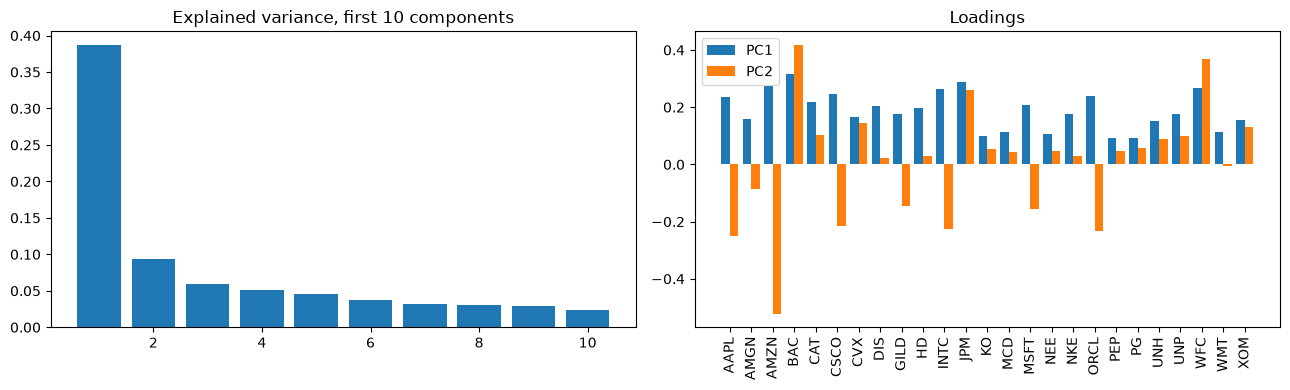

In [6]:
eigvals, Vt, scores = pca_svd(stocks.to_numpy())
if Vt[0].sum() < 0:          # signs are arbitrary; flip so the market factor reads positive
    Vt[0] = -Vt[0]
explained = eigvals / eigvals.sum()
print(explained[:5].round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, 11), explained[:10])
ax[0].set_title("Explained variance, first 10 components")
x = np.arange(len(stocks.columns))
ax[1].bar(x - 0.2, Vt[0], width=0.4, label="PC1")
ax[1].bar(x + 0.2, Vt[1], width=0.4, label="PC2")
ax[1].set_xticks(x)
ax[1].set_xticklabels(stocks.columns, rotation=90)
ax[1].legend()
ax[1].set_title("Loadings")
plt.tight_layout()
plt.show()

## Conclusions

**1. Speed.** On a 2,500-day, 25-asset matrix, `cov_loops` took 2.6 s, `cov_vec` took 765 µs and `np.cov` took 906 µs. The vectorised version is about 3,400 times faster than the loops, and slightly faster than NumPy's own function, which does extra input checks. All three give the same numbers (`np.allclose` is True). The loop version is the definition, and the matrix form Xc′Xc/(n−1) is the same calculation done by optimised library code.

**2. Rank.** With 10 days and 25 assets the covariance matrix has rank 9, which is n−1. Centring uses up one degree of freedom, so 10 days span only 9 independent directions. A 25 × 25 matrix with rank 9 is singular and cannot be inverted. This matters for Markowitz, which needs the inverse. On the full sample the covariance is symmetric and its smallest eigenvalue is 4.5e-5, which is positive but tiny compared with the largest. The correlation matrix from `corr_from_cov` matches pandas exactly.

**3. Conditioning.** `cond_XtX` is the square of `cond_X` at every row (for example 2.2e2 becomes 4.6e4). The normal-equations error grows with it: 1e-11 at eps = 1e-2, 2e-7 at 1e-4, 3e-4 at 1e-6, and 12.7 at 1e-8. At eps = 1e-8 `cond_XtX` is about 1e16, near 1/(machine precision), so X′X is numerically singular and the estimate of a true coefficient of 1 is wrong by more than 12. QR and SVD stay at about 1e-9 even there. The normal equations are already about a million times less accurate than QR at eps = 1e-4, and become practically unusable by eps = 1e-6. QR and SVD are far more reliable when the columns are nearly collinear, which is common with highly correlated stocks.

**4. Betas.** For AAPL, all four methods (normal equations, QR, SVD, statsmodels) give identical results: alpha 0.0006 per day and beta 1.15. The lowest betas are PG (0.50), PEP (0.51) and KO (0.52), then MCD, WMT and NEE: defensive consumer and utility stocks. The highest are BAC (1.48), JPM (1.39) and INTC (1.29), then WFC and AMZN: banks and cyclical or tech names. This ordering matches what is expected, since banks amplify market moves and staples dampen them. These betas use daily log returns over the full 2000-2025 sample, so they are one average over very different regimes.

**5. PCA.** The first component explains 38.6% of total variance, and the next four explain 9.4%, 6.0%, 5.1% and 4.6%. One market-wide factor therefore carries far more variance than any other, and the rest decay slowly. PC1 is the "market" factor, with loadings of the same sign across the stocks. PC2 and later components separate groups of stocks (see the loadings bar chart for which ones are on opposite sides). Because the PCA uses covariance, volatile stocks and those with extreme days (AAPL, PG) get more weight. A PCA on the correlation matrix would treat all stocks equally.

## Drill D: Markowitz by Lagrange multipliers

**Problem.** Choose weights $w$ to minimise $\tfrac12 w'\Sigma w$ subject to $1'w = 1$ and $\mu'w = m$.

**Lagrangian.** $L = \tfrac12 w'\Sigma w - \lambda(1'w - 1) - \gamma(\mu'w - m)$

**First-order condition.** $\partial L/\partial w = \Sigma w - \lambda 1 - \gamma\mu = 0$, so
$$w = \Sigma^{-1}(\lambda 1 + \gamma\mu).$$

**Constants.** $A = 1'\Sigma^{-1}1,\quad B = 1'\Sigma^{-1}\mu,\quad C = \mu'\Sigma^{-1}\mu,\quad D = AC - B^2$.

**Multipliers.** Substituting $w$ into the two constraints gives two linear equations:
$$\lambda A + \gamma B = 1, \qquad \lambda B + \gamma C = m$$
with solution $\lambda = (C - Bm)/D$ and $\gamma = (Am - B)/D$.

**Minimum variance (no return target).** Drop the second constraint, so $\gamma = 0$ and $\lambda = 1/A$:
$$w = \frac{\Sigma^{-1}1}{1'\Sigma^{-1}1}.$$

**Frontier.** Since $w'\Sigma w = w'(\lambda 1 + \gamma\mu) = \lambda + \gamma m$, the variance of the optimal portfolio is
$$\sigma^2(m) = \frac{Am^2 - 2Bm + C}{D}.$$
This is a parabola in $m$, so the curve $(\sigma, m)$ is a hyperbola. Its leftmost point is at $m = B/A$ with $\sigma^2 = 1/A$, the minimum-variance portfolio.

**Tangency (maximum Sharpe).** The Sharpe ratio $(\mu - r_f 1)'w / \sqrt{w'\Sigma w}$ does not change if $w$ is rescaled, so we maximise it and then rescale to $1'w = 1$. The first-order condition gives $\Sigma w \propto (\mu - r_f 1)$, so
$$w \propto \Sigma^{-1}(\mu - r_f 1).$$

**Units.** $\mu$ and $\Sigma$ must both be annualised (daily mean × 252, daily covariance × 252). Mixing annual means with daily covariances gives nonsense weights.

In [7]:
from quantlab.returns import simple_returns
from quantlab.optimizers import (
    min_variance_weights, target_return_weights, tangency_weights,
    solve_numeric, portfolio_stats, frontier,
)

R = simple_returns(load_prices()).drop(columns="^GSPC")   # simple returns for portfolio arithmetic
tickers = list(R.columns)
mu = R.mean().to_numpy() * 252
cov = cov_vec(R.to_numpy()) * 252
p = len(mu)
print(p, mu.round(3).min(), mu.round(3).max())

25 0.084 0.3


In [8]:
w_mv = min_variance_weights(cov)
m = float(np.median(mu))
w_cf = target_return_weights(mu, cov, m)
w_num = solve_numeric(mu, cov, m)

print("max |closed - numeric|:", np.abs(w_cf - w_num).max())
print("sum of weights:", w_cf.sum(), " return:", w_cf @ mu, " target:", m)
print("min-variance portfolio (return, vol):", portfolio_stats(w_mv, mu, cov))

max |closed - numeric|: 5.14648129451567e-06
sum of weights: 1.0000000000000002  return: 0.14587715681643887  target: 0.14587715681643884
min-variance portfolio (return, vol): (0.12153475384967813, 0.14925646221974265)


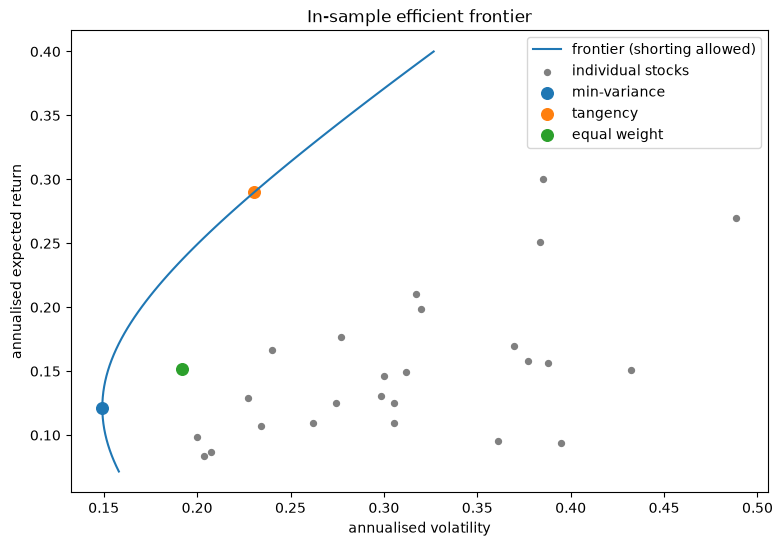

In [9]:
rf = 0.0                       # stated assumption: zero risk-free rate
w_tan = tangency_weights(mu, cov, rf)
w_eq = np.ones(p) / p

m0 = w_mv @ mu
targets = np.linspace(m0 - 0.05, 0.40, 80)
vols, _ = frontier(mu, cov, targets)

stock_vol = np.sqrt(np.diag(cov))
plt.figure(figsize=(9, 6))
plt.plot(vols, targets, label="frontier (shorting allowed)")
plt.scatter(stock_vol, mu, s=18, color="grey", label="individual stocks")
for name, w in [("min-variance", w_mv), ("tangency", w_tan), ("equal weight", w_eq)]:
    ret, vol = portfolio_stats(w, mu, cov)
    plt.scatter(vol, ret, s=70, label=name)
plt.xlabel("annualised volatility")
plt.ylabel("annualised expected return")
plt.legend()
plt.title("In-sample efficient frontier")
plt.show()

In [10]:
for name, w in [("min-variance", w_mv), ("tangency", w_tan)]:
    s = pd.Series(w, index=tickers)
    print(f"{name}: negative weights = {(s < 0).sum()}, min = {s.min():.2f}, max = {s.max():.2f}, gross = {s.abs().sum():.2f}")

pd.DataFrame({"min_var": w_mv, "tangency": w_tan}, index=tickers).round(3).sort_values("tangency")

min-variance: negative weights = 6, min = -0.05, max = 0.16, gross = 1.30
tangency: negative weights = 10, min = -0.18, max = 0.33, gross = 3.05


,min_var,tangency
CSCO,-0.009,-0.181
INTC,-0.015,-0.159
DIS,0.008,-0.134
BAC,-0.032,-0.120
KO,0.139,-0.120
HD,-0.050,-0.114
AMGN,0.031,-0.087
XOM,0.056,-0.078
PG,0.161,-0.019
CVX,0.019,-0.015


## Conclusions (Drill D)

**1. Closed form against the solver.** The closed-form target-return portfolio and the scipy solution differ by at most 5.1e-6 in any weight, within the 1e-5 tolerance of the test. The closed-form weights sum to 1 (to 2e-16) and their expected return equals the target of 14.59% (to 1e-16), so both constraints hold. Two independent methods agree, which confirms the derivation and the code. The small difference comes from the solver's stopping tolerance, not from the closed form, which is exact.

**2. Minimum-variance portfolio.** It has an expected return of 12.2% and a volatility of 14.9% a year. That volatility is lower than every one of the 25 stocks and than the S&P 500 (about 19%), which shows the diversification benefit of the covariance matrix. It needs 6 negative weights, but they are small (the most negative is -5%), and the gross exposure (sum of absolute weights) is 1.30, so it holds roughly 115% long and 15% short. The largest positions are the low-volatility defensive names: PG (16%), WMT (16%), PEP (15%), MCD (15%) and KO (14%).

**3. Tangency portfolio.** It is far more extreme. It has 10 negative weights, a range from -18% (CSCO) to +33% (NEE), and a gross exposure of 3.05, which means about 203% long and 103% short for every unit of capital. Its biggest long positions are NEE, AAPL (30%), GILD (21%) and UNH (19%), the stocks with the highest sample mean returns. Its biggest shorts are CSCO, INTC, DIS, BAC, KO and HD, mostly stocks with low or weak sample means. The weights follow the estimated means.

**4. Why the tangency weights are fragile.** Minimum variance uses only the covariance matrix, but the tangency portfolio is driven by the vector of means. Means are estimated with large error: a stock with 30% annual volatility observed over 26 years has a standard error on its mean of about 0.30/√26, roughly 6 percentage points, which is similar to the whole spread of mean returns across these stocks (8.4% to 30%). Much of the difference between "great" and "terrible" stocks in this sample is noise. The optimiser treats the estimates as true and levers up on them, which is why it holds 200% long and 100% short.

**5. In-sample only.** The frontier and the tangency portfolio are computed with the same data they are evaluated on, so they show the best the optimiser could do with perfect hindsight about means and covariances. They are not returns an investor could have earned. The out-of-sample question, whether such portfolios survive when the inputs must be estimated from past data only, is what the Ledoit–Wolf, simulation and walk-forward backtest steps will test.